In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("../data/superstore.csv", encoding="latin-1")
df.shape

(9994, 21)

In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [8]:
#
df.columns = (df.columns.str.strip()
                        .str.lower()
                        .str.replace(" ", "_")
                        .str.replace("-", "_"))
df.columns.tolist()

['row_id',
 'order_id',
 'order_date',
 'ship_date',
 'ship_mode',
 'customer_id',
 'customer_name',
 'segment',
 'country',
 'city',
 'state',
 'postal_code',
 'region',
 'product_id',
 'category',
 'sub_category',
 'product_name',
 'sales',
 'quantity',
 'discount',
 'profit']

In [9]:
#
df["order_date"] = pd.to_datetime(df["order_date"], format="%m/%d/%Y")
df["ship_date"]  = pd.to_datetime(df["ship_date"],  format="%m/%d/%Y")
df[["order_date", "ship_date"]].dtypes

order_date    datetime64[us]
ship_date     datetime64[us]
dtype: object

In [10]:
#
df["postal_code"] = df["postal_code"].astype(str).str.zfill(5)
df["postal_code"].head()

0    42420
1    42420
2    90036
3    33311
4    33311
Name: postal_code, dtype: str

In [11]:
#
df["profit_margin_pct"] = np.where(df["sales"] > 0,
                                   (df["profit"] / df["sales"] * 100).round(2), 0)
df["order_year"]    = df["order_date"].dt.year
df["order_month"]   = df["order_date"].dt.month
df["month_name"]    = df["order_date"].dt.month_name()
df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days

df["discount_band"] = pd.cut(
    df["discount"],
    bins=[-0.01, 0, 0.10, 0.20, 0.30, 0.50, 1.0],
    labels=["No discount", "Up to 10%", "11-20%", "21-30%", "31-50%", "Over 50%"]
)
df[["profit_margin_pct", "order_year", "shipping_days", "discount_band"]].head()

,profit_margin_pct,order_year,shipping_days,discount_band
0,16.00,2016,3,No discount
1,30.00,2016,3,No discount
2,47.00,2016,4,No discount
3,-40.00,2015,7,31-50%
4,11.25,2015,7,11-20%


In [14]:
#
print(df.shape)
print("Missing values:", df.isna().sum().sum())
print("Date range:", df["order_date"].min(), "to", df["order_date"].max())
print("Shipping days:", df["shipping_days"].min(), "to", df["shipping_days"].max())
print("Sales <= 0 rows:", (df["sales"] <= 0).sum())

(9994, 27)
Missing values: 0
Date range: 2014-01-03 00:00:00 to 2017-12-30 00:00:00
Shipping days: 0 to 7
Sales <= 0 rows: 0


In [13]:
#
df.to_csv("../data/superstore_clean.csv", index=False)

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

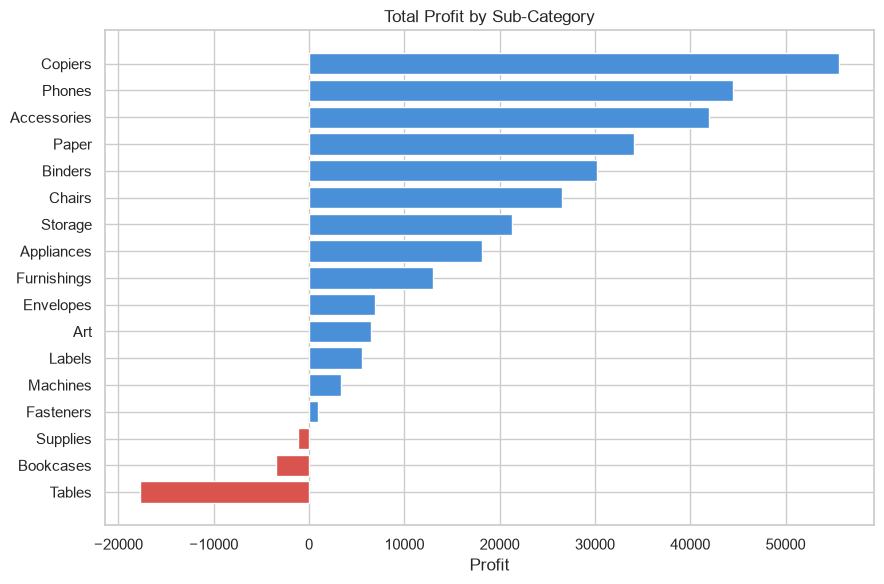

In [16]:
#
sub = df.groupby("sub_category")["profit"].sum().sort_values()

plt.figure(figsize=(9, 6))
colors = ["#d9534f" if v < 0 else "#4a90d9" for v in sub.values]
plt.barh(sub.index, sub.values, color=colors)
plt.title("Total Profit by Sub-Category")
plt.xlabel("Profit")
plt.tight_layout()
plt.savefig("../report/profit_by_subcategory.png", dpi=150)
plt.show()

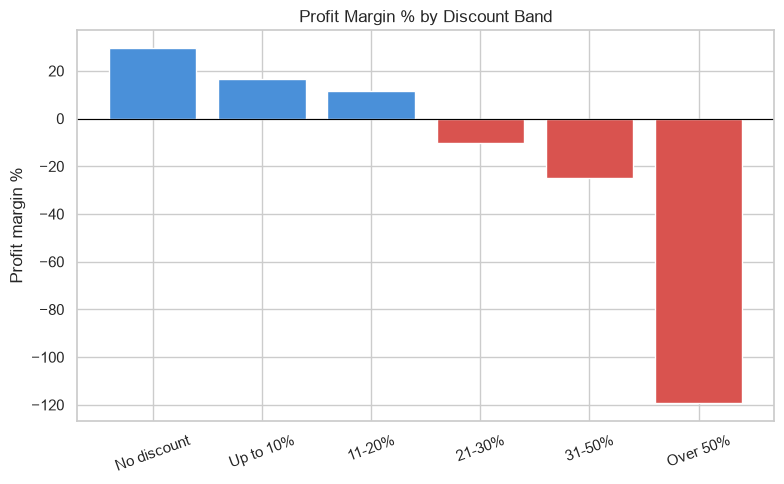

In [17]:
#
band = df.groupby("discount_band", observed=True).agg(
    sales=("sales", "sum"), profit=("profit", "sum"))
band["margin_pct"] = band["profit"] / band["sales"] * 100

plt.figure(figsize=(8, 5))
colors = ["#d9534f" if v < 0 else "#4a90d9" for v in band["margin_pct"]]
plt.bar(band.index.astype(str), band["margin_pct"], color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Profit Margin % by Discount Band")
plt.ylabel("Profit margin %")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../report/margin_by_discount_band.png", dpi=150)
plt.show()

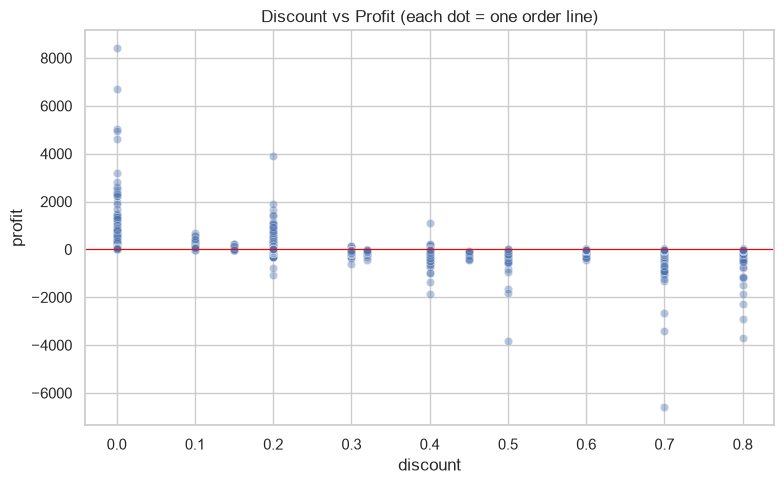

In [19]:
#
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="discount", y="profit", alpha=0.4)
plt.axhline(0, color="red", linewidth=0.8)
plt.title("Discount vs Profit (each dot = one order line)")
plt.tight_layout()
plt.savefig("../report/discount_vs_profit.png", dpi=150)
plt.show()

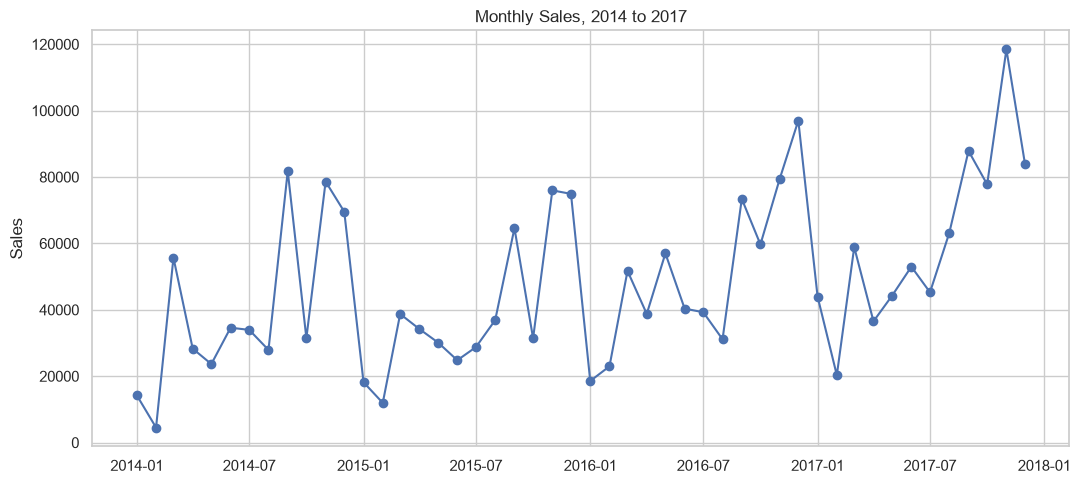

In [20]:
#
monthly = (df.groupby(["order_year", "order_month"])["sales"]
             .sum().reset_index())
monthly["period"] = pd.to_datetime(
    monthly["order_year"].astype(str) + "-" + monthly["order_month"].astype(str) + "-01")

plt.figure(figsize=(11, 5))
plt.plot(monthly["period"], monthly["sales"], marker="o")
plt.title("Monthly Sales, 2014 to 2017")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("../report/monthly_sales.png", dpi=150)
plt.show()

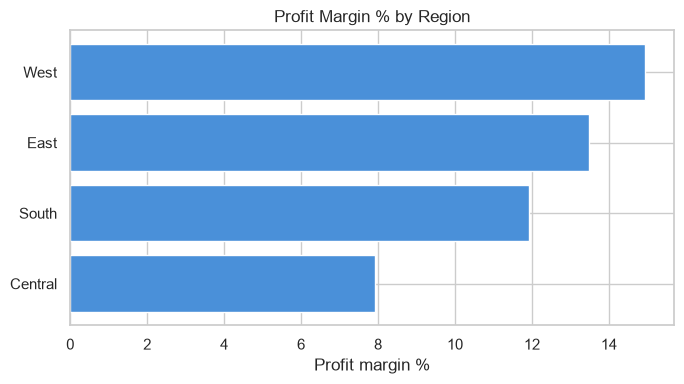

In [21]:
#

reg = df.groupby("region").agg(sales=("sales", "sum"), profit=("profit", "sum"))
reg["margin_pct"] = reg["profit"] / reg["sales"] * 100
reg = reg.sort_values("margin_pct")

plt.figure(figsize=(7, 4))
plt.barh(reg.index, reg["margin_pct"], color="#4a90d9")
plt.title("Profit Margin % by Region")
plt.xlabel("Profit margin %")
plt.tight_layout()
plt.savefig("../report/margin_by_region.png", dpi=150)
plt.show()

In [22]:
#
snapshot_date = df["order_date"].max() + pd.Timedelta(days=1)

rfm = df.groupby(["customer_id", "customer_name"]).agg(
    recency=("order_date", lambda x: (snapshot_date - x.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("sales", "sum"),
    profit=("profit", "sum")
).reset_index()

rfm["monetary"] = rfm["monetary"].round(2)
rfm["profit"] = rfm["profit"].round(2)
print(rfm.shape)
rfm.head()

(793, 6)


,customer_id,customer_name,recency,frequency,monetary,profit
0,AA-10315,Alex Avila,185,5,5563.56,-362.88
1,AA-10375,Allen Armold,20,9,1056.39,277.38
2,AA-10480,Andrew Allen,260,4,1790.51,435.83
3,AA-10645,Anna Andreadi,56,6,5086.93,857.80
4,AB-10015,Aaron Bergman,416,3,886.16,129.35


In [23]:
#
rfm["r_score"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["f_score"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm[["customer_name", "recency", "frequency", "monetary", "r_score", "f_score", "m_score"]].head()

,customer_name,recency,frequency,monetary,r_score,f_score,m_score
0,Alex Avila,185,5,5563.56,2,2,5
1,Allen Armold,20,9,1056.39,5,5,2
2,Andrew Allen,260,4,1790.51,1,1,3
3,Anna Andreadi,56,6,5086.93,3,3,5
4,Aaron Bergman,416,3,886.16,1,1,1


In [24]:
#
def assign_segment(row):
    r, f = row["r_score"], row["f_score"]
    if r >= 4 and f >= 4:
        return "Champions"
    elif r >= 3 and f >= 3:
        return "Loyal Customers"
    elif r >= 4 and f <= 2:
        return "New / Recent Customers"
    elif r <= 2 and f >= 4:
        return "At Risk (Big Buyers)"
    elif r <= 2 and f <= 2:
        return "Lost Customers"
    else:
        return "Need Attention"

rfm["segment"] = rfm.apply(assign_segment, axis=1)
rfm["segment"].value_counts()

segment
Lost Customers            171
Champions                 167
Loyal Customers           164
Need Attention            122
New / Recent Customers     89
At Risk (Big Buyers)       80
Name: count, dtype: int64

In [25]:
#
seg = rfm.groupby("segment").agg(
    customers=("customer_id", "count"),
    avg_recency_days=("recency", "mean"),
    avg_orders=("frequency", "mean"),
    total_sales=("monetary", "sum"),
    total_profit=("profit", "sum")
).round(1).sort_values("total_sales", ascending=False)

seg["profit_margin_pct"] = (seg["total_profit"] / seg["total_sales"] * 100).round(1)
seg

,customers,avg_recency_days,avg_orders,total_sales,total_profit,profit_margin_pct
segment,,,,,,
Champions,167,25.5,9.0,675849.8,82573.5,12.2
Loyal Customers,164,59.4,7.3,537225.2,59461.4,11.1
At Risk (Big Buyers),80,205.5,8.7,349534.9,61914.1,17.7
Lost Customers,171,377.5,3.7,287983.0,31938.9,11.1
Need Attention,122,162.7,5.1,286756.5,26301.4,9.2
New / Recent Customers,89,26.5,4.2,159851.4,24207.9,15.1


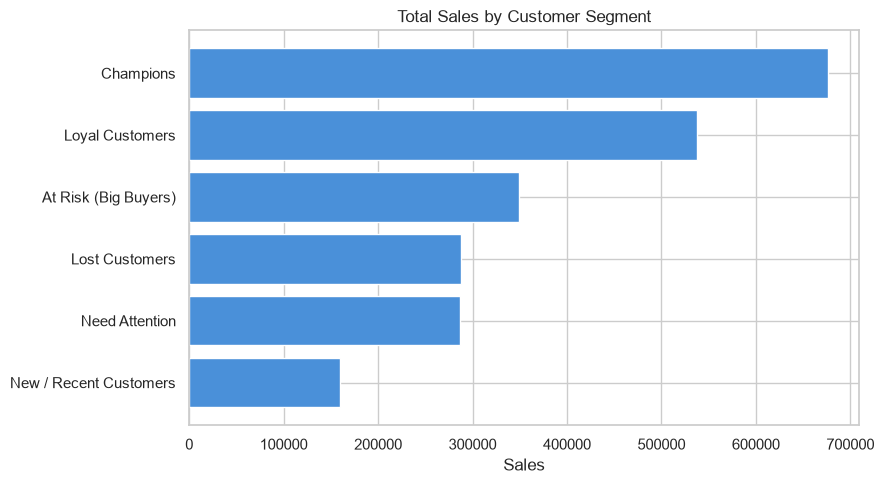

In [26]:
#
plt.figure(figsize=(9, 5))
seg_sorted = seg.sort_values("total_sales")
plt.barh(seg_sorted.index, seg_sorted["total_sales"], color="#4a90d9")
plt.title("Total Sales by Customer Segment")
plt.xlabel("Sales")
plt.tight_layout()
plt.savefig("../report/rfm_segments.png", dpi=150)
plt.show()

In [27]:
#
rfm.to_csv("../data/rfm_segments.csv", index=False)